In [1]:
import os
import re
import datetime
import pathlib

import pandas as pd
import numpy as np
import geopandas as gpd
import movingpandas as mpd
import matplotlib.pyplot as plt

import dask_geopandas as dgpd
import dask.dataframe as dd
import dask.distributed

/Users/hemert/projects/scheepvaart-gedrag-ark/.venv/lib/python3.13/site-packages/movingpandas/__init__.py:41: UserWarning: Missing optional dependencies. To use the trajectory smoother classes please install Stone Soup (see https://stonesoup.readthedocs.io/en/latest/#installation).
  warnings.warn(e.msg, UserWarning)


In [2]:
src_dir = pathlib.Path('~').expanduser() / 'data/ais'

In [3]:
ark_gdf = gpd.read_file(src_dir / 'ARK.gpkg').dissolve()
ark_gdf = ark_gdf.set_crs("EPSG:28992")
ark_geometry = ark_gdf.geometry.iloc[0]

In [4]:
cluster = dask.distributed.LocalCluster(n_workers=10, memory_limit="4GB")
cluster

LocalCluster(ded0bda7, 'tcp://127.0.0.1:50033', workers=10, threads=10, memory=37.25 GiB)

2026-10-15 16:01:07,555 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 49464be0828faadc1fa0b4ea6c062d05 initialized by task ('shuffle-transfer-49464be0828faadc1fa0b4ea6c062d05', 44) executed on worker tcp://127.0.0.1:50100
2026-10-15 16:01:09,623 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 49464be0828faadc1fa0b4ea6c062d05 deactivated due to stimulus 'task-finished-1792072869.62202'


In [5]:
client = dask.distributed.Client(address=cluster)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 10
Total threads: 10,Total memory: 37.25 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:50033,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:50056,Total threads: 1
Dashboard: http://127.0.0.1:50057/status,Memory: 3.73 GiB
Nanny: tcp://127.0.0.1:50036,


In [6]:
gddf = dgpd.read_parquet(src_dir / "20261009T101648Z-1f377771-maarssen/data/year=2026/")
gddf.head()

,timestamp_recv,mmsi_hash,longitude,latitude,length,beam,objecttype,cog,sog,heading,shiptypeais,geom,year,month,day
0,2026-07-01 00:00:00.749000+00:00,dd11e37f56f9241fba8a76a72596c323,5.05010,52.130660,30.0,10.0,VESA,0.0,0.0,NaN,69,POINT (5.0501 52.13066),2026,7,1
1,2026-07-01 00:00:01.890000+00:00,5f69ae2a2f30b136ba7ba2dc4558e7b4,5.07665,52.113123,NaN,NaN,BASE,NaN,NaN,NaN,NaN,POINT (5.07665 52.11312),2026,7,1
2,2026-07-01 00:00:01.905000+00:00,5f69ae2a2f30b136ba7ba2dc4558e7b4,5.07665,52.113123,NaN,NaN,BASE,NaN,NaN,NaN,NaN,POINT (5.07665 52.11312),2026,7,1
3,2026-07-01 00:00:05.016000+00:00,2650cfc875cb3852f9701a08564117c1,5.03818,52.134152,110.0,10.0,VESA,132.0,7.2,131.0,80,POINT (5.03818 52.13415),2026,7,1
4,2026-07-01 00:00:08.563000+00:00,17ad9316e3270a25e76a040714b819da,5.04968,52.130907,20.0,10.0,VESA,0.0,0.0,NaN,69,POINT (5.04968 52.13091),2026,7,1


In [7]:
counts = (
    gddf
    .groupby(['mmsi_hash'])
    .count()
    # pick a column that always has data, so that our count represents the number of records
    .sort_values('latitude', ascending=False)
    
)

In [8]:
counts.head(npartitions=-1, n=10)

,timestamp_recv,longitude,latitude,length,beam,objecttype,cog,sog,heading,shiptypeais,geom,year,month,day
mmsi_hash,,,,,,,,,,,,,,
5f69ae2a2f30b136ba7ba2dc4558e7b4,1584963,1584963,1584963,0,0,1584963,0,0,0,0,1584963,1584963,1584963,1584963
dd11e37f56f9241fba8a76a72596c323,711619,711619,711619,711602,711602,711619,711294,711295,0,711602,711619,711619,711619,711619
17ad9316e3270a25e76a040714b819da,549645,549645,549645,546481,546481,549645,549477,549477,0,546427,549645,549645,549645,549645
ab9a18bcc506bcd3b94fe0c52b3e0e90,266892,266892,266892,266859,266859,266892,8500,266892,0,266834,266892,266892,266892,266892
876ff1f734b3bee2a77e0f63bdae09fd,128516,128516,128516,128515,128515,128516,128494,128494,0,128515,128516,128516,128516,128516
605845f66ad24512e6918cfbe28b77d6,79816,79816,79816,79796,79796,79816,79505,79505,0,79796,79816,79816,79816,79816
36515fd83ceef05aa7209ea714e6b2fc,78509,78509,78509,78480,78480,78509,78505,78505,0,78447,78509,78509,78509,78509
320b32cdc43e7d5e8b40c828f80a84a1,69253,69253,69253,69219,69219,69253,69159,69159,0,69219,69253,69253,69253,69253
681723c468b547c3f7b3bf3c1bdc0d11,58994,58994,58994,58994,58994,58994,58994,58994,58980,58994,58994,58994,58994,58994


In [9]:
ship_name = 'ab9a18bcc506bcd3b94fe0c52b3e0e90'
example_ship_gdf = gddf[gddf['mmsi_hash'] == ship_name].compute()
example_ship_gdf_sorted = example_ship_gdf.sort_values('timestamp_recv')

In [10]:
example_ship_gdf_sorted['ship_length'] = example_ship_gdf_sorted['length'].copy()
example_ship_gdf_sorted['ship_width'] = example_ship_gdf_sorted['beam'].copy()

<Axes: xlabel='x', ylabel='y'>

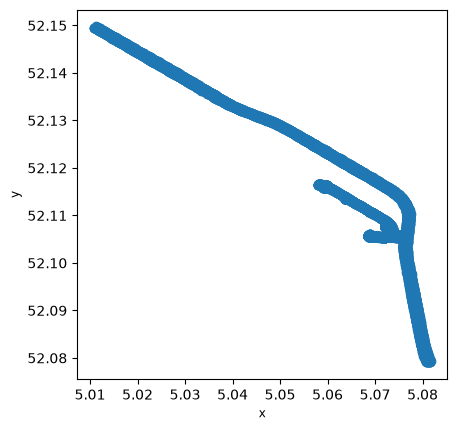

In [11]:
selected_gdf = example_ship_gdf_sorted.copy()
selected_gdf.plot()

In [12]:
gddf = gddf.set_crs('EPSG:4326')
ark_gdf = ark_gdf.to_crs("EPSG:4326")

gddf_filtered = dgpd.sjoin(gddf, ark_gdf, how='inner')[gddf.columns]
# gddf_filtered = gddf_filtered.set_crs('EPSG:4326')
gddf_filtered = gddf_filtered.to_crs('EPSG:28992')

In [13]:
gddf_filtered.to_parquet(
    src_dir / "filtered_ark_ais_data",
    partition_on=["year", "month", "day"],
)

In [14]:
def df_to_splitted(gdf, timestamp_column = 'timestamp_recv', id_column='mmsi_hash'):
    # time encode
    gdf['t'] = df[timestamp_column].apply(
        lambda x: datetime.datetime.fromisoformat(x).replace(tzinfo=None)
    )
    # reproject (for calculations in m)
    gdf_rd = gdf.to_crs('EPSG:28992')

    # trajectorize
    ship_id = gdf[id_column].iloc[0]
    traj = mpd.Trajectory(gdf_rd, t='t', traj_id=ship_id, crs='EPSG:28992')

    # split by day
    splitter = mpd.TemporalSplitter(traj)
    traj_by_day = splitter.split(mode='day')

    # simplify (bit slow)
    generalizer = mpd.DouglasPeuckerGeneralizer(traj_by_day)
    traj_simplified = generalizer.generalize(tolerance=5.0)
    splitted_observation_gaps = mpd.ObservationGapSplitter(traj_simplified).split(gap=datetime.timedelta(minutes=10))
    
    # detect stops (very slow)
    traj_stop_splitted = mpd.StopSplitter(splitted_observation_gaps).split(min_length=5, max_diameter=50, min_duration=datetime.timedelta(minutes=10))
    
    # add extra info
    traj_stop_splitted.add_acceleration(overwrite=True)
    traj_stop_splitted.add_angular_difference(overwrite=True)
    traj_stop_splitted.add_direction(overwrite=True)
    traj_stop_splitted.add_speed(overwrite=True)
    traj_stop_splitted.add_traj_id(overwrite=True)

    # project back to wgs84
    trajectories_wgs84 = [traj_i.to_crs('EPSG:4326') for traj_i in  traj_stop_splitted.trajectories]
    # collect results
    result = mpd.TrajectoryCollection(trajectories_wgs84, crs='EPSG:4326')
    return result

In [25]:
selected_gdf = selected_gdf.set_crs("EPSG:4326")
selected_gdf.to_file(src_dir / 'example_gdf.gpkg')

In [37]:
ark_gdf = gpd.read_file(src_dir / 'ARK.gpkg').dissolve()
ark_gdf = ark_gdf.set_crs("EPSG:28992")
ark_geometry = ark_gdf.geometry.iloc[0]

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

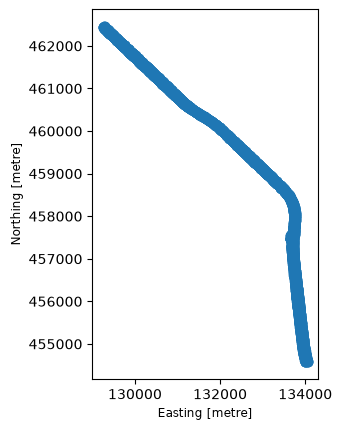

In [43]:
selected_gdf.to_crs("EPSG:28992").intersection(ark_gdf.geometry.iloc[0]).plot()